# Data exploration: what predicts a union election win?

**Working notebook, not the final product.** It goes through the whole exploration: the target,
every column on its own, every feature against the target, and pairs of features. Then it ranks
what looks strongest, takes a closer look at **days from petition to election**, and builds
candidate explanatory figures for the midterm report. My notes and recommendations are in the
markdown cells after each step.

**What the midterm asks for:** explore the dataset, make lots of exploratory figures, and put
**3 explanatory figures** in the report, each with a catchy headline and a clear message.

**Which plot for which columns (lecture 4):**

| | continuous | categorical |
|---|---|---|
| **continuous** | scatter plot, heatmap | category-specific histograms, box plot, violin plot |
| **categorical** | category-specific histograms, box plot, violin plot | stacked bar plot |

Our target `union_won` is 0/1, so next to the lecture plots I use one more: the **win rate per
group**, the mean of `union_won` within each bin or category. It answers "does this feature move
the odds?" directly, so the explanatory figures use it.

**Contents**
1. Setup and a first look
2. The target
3. One column at a time
4. Each feature vs. the target
5. Pairs of features
6. Ranking: which features matter most?
7. Closer look: days from petition to election
8. Candidate explanatory figures for the report
9. Recommendations and to-dos

**Short version** (details in sections 6 to 9; the numbers are printed in the cells below):
- Unions win **70.8%** of the 15,312 elections.
- **Days to election** has a clear pattern: **86%** of elections held within 2 weeks of the
  petition are won, but only **43%** of those held more than a year after it. Faster elections
  win more **under every set of NLRB rules**, for every unit size, and whether or not the employer
  has a lawyer, so it's not just a stand-in for one of those.
- The NLRB's own rule changes (2015, 2020, 2023) moved the median wait between **23 and 38 days**
  almost overnight. This is the most interesting story in the data.
- Other strong signals: **unit size** (small units win more), **employer has a lawyer**
  (85% → 69%), **parent union** (48% to 89%), and **year** (win rate up from 63% to 77%).
- Weak or no signal: petitioner's lawyer, election month, census region.
- Recommended report figures: see section 9.

## 1. Setup and a first look

In [1]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt

pd.set_option('display.width', 200)

# same look for every figure: no top/right border, light grid behind the data
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#e6e6e6'
plt.rcParams['axes.axisbelow'] = True

BLUE = '#2a78d6'        # main color
LIGHT_BLUE = '#86b6ef'  # lighter step of the same blue, for ordered pairs (e.g. faster / slower)
ORANGE = '#eb6834'      # contrast color (e.g. won vs lost)
GRAY = '#9a9a9a'        # reference lines and context

df = pd.read_csv('../data/elections_clean.csv', parse_dates=['file_date', 'election_date', 'petition_date'])
print(df.shape)
print(df.dtypes)

(15312, 24)
fiscal_year                           int64
case_number                             str
case_type                               str
region                                int64
case_name                               str
employer                                str
city                                    str
state                                   str
census_region                           str
union_name                              str
parent_union                            str
eligible                            float64
file_date                    datetime64[us]
election_date                datetime64[us]
n_participants                      float64
employer_has_lawyer                 float64
n_employer_lawyers                  float64
employer_law_firms                      str
petitioner_has_lawyer               float64
n_petitioner_lawyers                float64
has_intervenor                      float64
petition_date                datetime64[us]
days_petition_to_ele

In [2]:
df.head()

,fiscal_year,case_number,case_type,region,case_name,employer,city,state,census_region,union_name,...,n_participants,employer_has_lawyer,n_employer_lawyers,employer_law_firms,petitioner_has_lawyer,n_petitioner_lawyers,has_intervenor,petition_date,days_petition_to_election,union_won
0,2015,06-RC-012276,RC,6,Point Park University,point park university,Pittsburgh,PA,Northeast,NEWSPAPER GUILD OF PITTSBURGH COMMUNICATIONS W...,...,8.0,1.0,1.0,"Jackson Lewis, P.C.",1.0,2.0,0.0,NaT,NaN,1
1,2012,09-RC-018160,RC,9,COLUMBUS SOUTHERN POWER COMPANY,columbus southern power,Columbus,OH,Midwest,INTERNATIONAL BROTHERHOOD OF ELECTRICAL WORKER...,...,3.0,1.0,1.0,Woods Rogers Vandeventer Black PLC,0.0,0.0,0.0,2007-08-06,38.0,0
2,2012,11-RC-006654,RC,11,APPALACHIAN POWER COMPANY,appalachian power,Roanoke,VA,South,"LOCAL UNION 978, INTERNATIONAL BROTHERHOOD OF ...",...,4.0,1.0,1.0,Woods Rogers PLC,0.0,0.0,0.0,2006-11-17,300.0,0
3,2014,05-RC-016210,RC,5,"Interbake Foods, LLC",interbake foods,Front Royal,VA,South,"BAKERY, CONFECTIONERY, TOBACCO, WORKERS AND GR...",...,5.0,1.0,2.0,NELSON MULLINS RILEY & SCARBOROUGH LLP; Perkin...,1.0,1.0,0.0,NaT,NaN,0
4,2012,16-RC-010844,RC,16,Plano Symphony Orchestra,plano symphony orchestra,Plano,TX,South,DALLAS/FORT WORTH PROFESSIONAL MUSICIANS ASSOC...,...,6.0,1.0,2.0,Littler Mendelson P.C.,1.0,2.0,0.0,2008-04-24,146.0,0


In [3]:
missing = df.isna().sum()
print(missing[missing > 0].sort_values())

city                             1
n_participants                   4
n_employer_lawyers               4
employer_has_lawyer              4
petitioner_has_lawyer            4
n_petitioner_lawyers             4
has_intervenor                   4
eligible                       157
petition_date                  707
days_petition_to_election      711
employer_law_firms            2489
file_date                    13984
dtype: int64


**Column types** (lecture 4: continuous / ordinal / categorical):

| column | type | notes |
|---|---|---|
| `days_petition_to_election` | continuous | **main feature**; 711 missing |
| `eligible` | continuous | unit size; very skewed; 157 missing |
| `n_participants`, `n_employer_lawyers`, `n_petitioner_lawyers` | ordinal (small counts) | |
| `employer_has_lawyer`, `petitioner_has_lawyer`, `has_intervenor` | categorical (yes/no) | 4 missing |
| `parent_union`, `census_region`, `state`, `region` | categorical | `region` is the NLRB office number. It's stored as a number but it's a category |
| `election_date` → year, month | ordinal | time; also what we split on |
| `employer` | ID | the GroupKFold group, **not** a feature |
| `case_number`, `case_name`, `union_name`, `city`, `employer_law_firms` | text / IDs | not used directly (law firms maybe later, see 3.7) |
| `file_date` | date | only in the early reports (91% missing); `petition_date` replaces it |
| `petition_date` | date | only used to compute days and the rule eras in section 7 |
| `union_won` | **target** | 1 = union certified |

In [4]:
df['year'] = df['election_date'].dt.year
df['month'] = df['election_date'].dt.month
print(df['year'].value_counts().sort_index())

year
2004       1
2007       2
2008       2
2009       3
2010       7
2011     390
2012    1125
2013    1144
2014    1150
2015    1306
2016    1091
2017    1126
2018     900
2019     917
2020     543
2021     643
2022    1177
2023     465
2024    1410
2025    1079
2026     831
Name: count, dtype: int64


**Note:** the reports start with cases that **closed** in October 2011 (FY2012). Elections
before that only show up if their case closed later, which makes them unusual, long cases (the
2004–2010 rows). For plots over time, I start in October 2011, or in 2012 for yearly plots.

## 2. The target

In [5]:
print(df['union_won'].value_counts())
print(df['union_won'].value_counts(normalize=True).round(3))

union_won
1    10839
0     4473
Name: count, dtype: int64
union_won
1    0.708
0    0.292
Name: proportion, dtype: float64


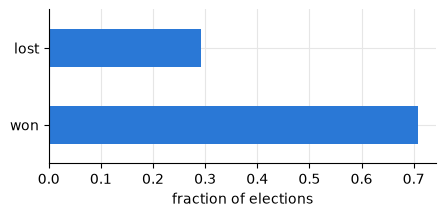

In [6]:
plt.figure(figsize=(5,2))
df['union_won'].map({1: 'won', 0: 'lost'}).value_counts(normalize=True).plot.barh(color=BLUE)
plt.xlabel('fraction of elections')
plt.ylabel('')
plt.show()

**Observations**
- Unions win **70.8%** (10,839 won, 4,473 lost). The classes are imbalanced but not extremely.
- A model that always says "won" is right 70.8% of the time, so **accuracy is a weak metric**
  here. Something like ROC AUC or log loss, or F-scores on the "lost" class, will say more.
  That's for the metric section of the report.

## 3. One column at a time

### 3.1 Days from petition to election (main feature)

In [7]:
print(df['days_petition_to_election'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

count    14601.000000
mean        42.979727
std         91.893197
min          2.000000
5%          16.000000
25%         24.000000
50%         31.000000
75%         41.000000
95%         79.000000
99%        300.000000
max       3444.000000
Name: days_petition_to_election, dtype: float64


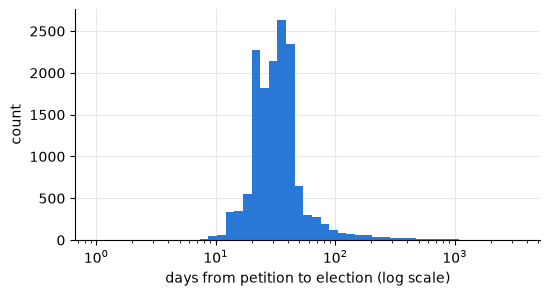

In [8]:
# long right tail, so log-spaced bins like the capital-gain example in lecture 4
days = df['days_petition_to_election'].dropna()

plt.figure(figsize=(6,3))
days.plot.hist(bins=np.logspace(np.log10(1), np.log10(days.max()), 50), color=BLUE)
plt.semilogx()
plt.xlabel('days from petition to election (log scale)')
plt.ylabel('count')
plt.show()

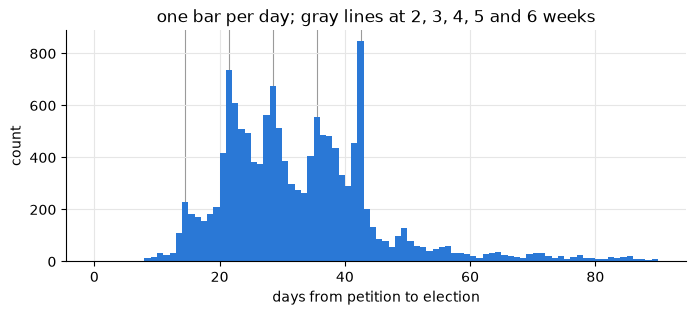

share of elections a whole number of weeks after the petition: 0.237


In [9]:
# zoom in on the first 90 days, one bar per day
plt.figure(figsize=(8,3))
days.plot.hist(bins=np.arange(0, 91), color=BLUE)
for week in [14, 21, 28, 35, 42]:
    plt.axvline(week + 0.5, color=GRAY, linewidth=0.8, zorder=0)
plt.xlabel('days from petition to election')
plt.ylabel('count')
plt.title('one bar per day; gray lines at 2, 3, 4, 5 and 6 weeks')
plt.show()

print('share of elections a whole number of weeks after the petition:', round((days % 7 == 0).mean(), 3))

**Observations**
- Median **31 days**, 95% of elections within 79 days, but a long tail up to 3,444 days (9+
  years). Those are litigated cases; `data/data_checks.md` (check 18) says they're real.
- **Spikes every 7 days** (14, 21, 28, 35, 42): about 24% of elections are a whole number of
  weeks after the petition, versus 1 in 7 (14%) by chance. Elections tend to be scheduled on the
  same weekday the petition was filed. The **42-day** spike is the biggest; section 7 checks
  where it comes from.
- **Feature engineering:** use `log(days)` or cap the tail for linear models (trees don't care).

### 3.2 Unit size (`eligible` voters)

count    15155.000000
mean        62.621973
std        335.195010
min          1.000000
10%          5.000000
25%         10.000000
50%         22.000000
75%         53.000000
90%        127.000000
99%        599.460000
max      35050.000000
Name: eligible, dtype: float64


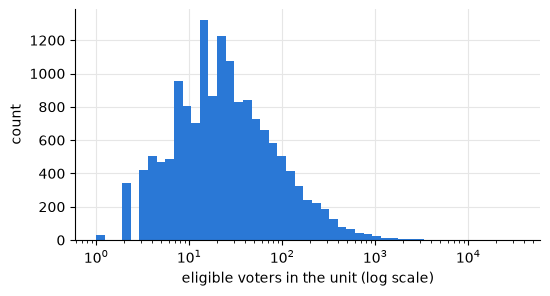

In [10]:
print(df['eligible'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

eligible = df['eligible'].dropna()
plt.figure(figsize=(6,3))
eligible.plot.hist(bins=np.logspace(0, np.log10(eligible.max()), 50), color=BLUE)
plt.semilogx()
plt.xlabel('eligible voters in the unit (log scale)')
plt.ylabel('count')
plt.show()

**Observations**
- Most units are small: median **22** voters, a quarter have 10 or fewer, and the largest has
  35,050. It's very skewed, so use `log10(eligible)`. On a log scale it looks roughly bell-shaped.
- 157 missing (set to missing on purpose during cleaning, see `data_checks.md` checks 9 and 11).

### 3.3 Count columns (ordinal)

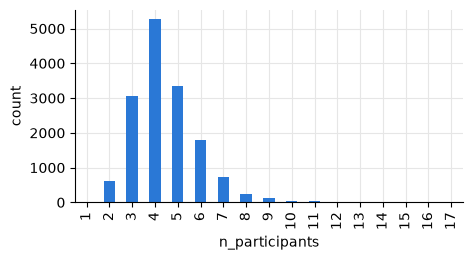

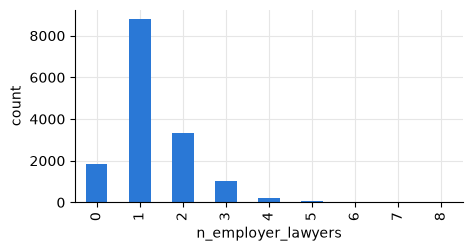

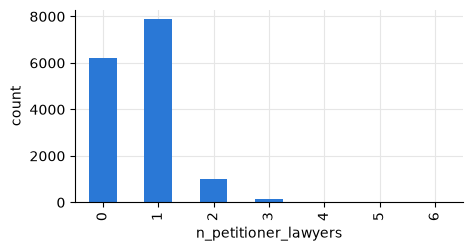

In [11]:
for col in ['n_participants', 'n_employer_lawyers', 'n_petitioner_lawyers']:
    plt.figure(figsize=(5,2.5))
    df[col].dropna().astype(int).value_counts().sort_index().plot.bar(color=BLUE)   # sort_index keeps the counts in order
    plt.xlabel(col)
    plt.ylabel('count')
    plt.show()

**Observations**
- Most cases have 3 to 5 participants (employer, union, and their lawyers).
- Most employers have **1** lawyer; a few have 4 or more. Most unions have 0 or 1.
- Long thin tails, so I cap them for the win-rate plots (8+, 4+, 3+).

### 3.4 Yes/no columns

In [12]:
for col in ['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']:
    print(df[col].value_counts(normalize=True).round(3), '\n')

employer_has_lawyer
1.0    0.879
0.0    0.121
Name: proportion, dtype: float64 

petitioner_has_lawyer
1.0    0.593
0.0    0.407
Name: proportion, dtype: float64 

has_intervenor
0.0    0.972
1.0    0.028
Name: proportion, dtype: float64 



**Observations**
- **88%** of employers have a lawyer, so the 12% without one are the unusual group.
- 59% of unions (petitioners) list a lawyer.
- An intervenor (a third party that joins the case) is rare: 2.8%, or 430 elections.

### 3.5 Unions

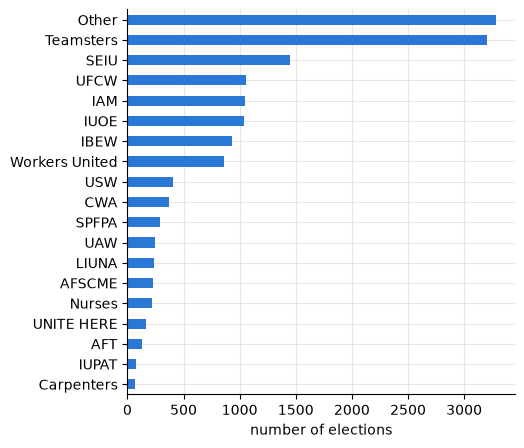

In [13]:
plt.figure(figsize=(5,5))
df['parent_union'].value_counts().sort_values().plot.barh(color=BLUE)
plt.xlabel('number of elections')
plt.ylabel('')
plt.show()

**Observations**
- "Other" (3,288) and Teamsters (3,200) are the biggest groups, followed by SEIU, UFCW, IAM and
  IUOE.
- **Workers United** (865) is almost all Starbucks (see 3.7).
- The smallest groups (Carpenters 66, IUPAT 79) will give noisy win rates.

### 3.6 Where

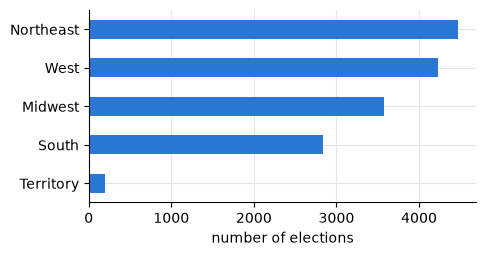

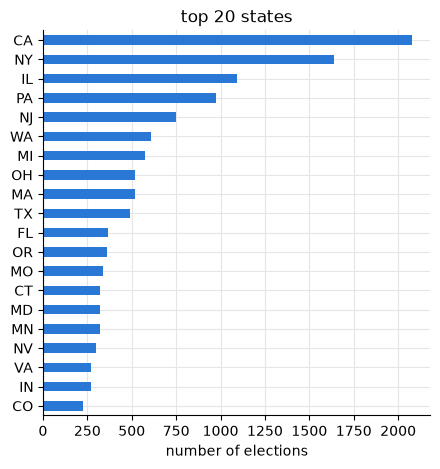

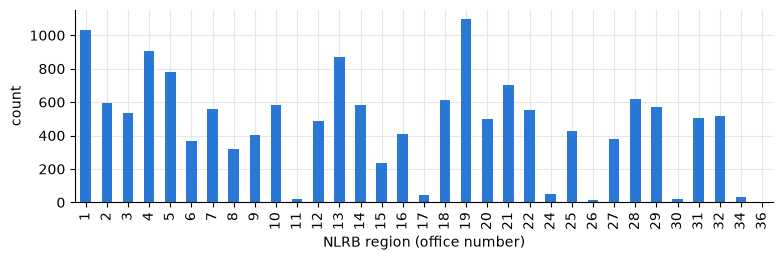

states/territories: 54   NLRB region numbers: 33


In [14]:
plt.figure(figsize=(5,2.5))
df['census_region'].value_counts().sort_values().plot.barh(color=BLUE)
plt.xlabel('number of elections')
plt.ylabel('')
plt.show()

plt.figure(figsize=(5,5))
df['state'].value_counts().head(20).sort_values().plot.barh(color=BLUE)
plt.xlabel('number of elections')
plt.ylabel('')
plt.title('top 20 states')
plt.show()

plt.figure(figsize=(9,2.5))
df['region'].value_counts().sort_index().plot.bar(color=BLUE)
plt.xlabel('NLRB region (office number)')
plt.ylabel('count')
plt.show()

print('states/territories:', df['state'].nunique(), '  NLRB region numbers:', df['region'].nunique())

**Observations**
- Northeast and West have the most elections. California, New York and Illinois lead the states.
- `state` has many categories; one-hot encoding makes a lot of columns, some of them tiny.
  `census_region` (5 groups) is the compact version.
- A few NLRB region numbers have only a handful of elections (e.g. 36). If we use `region`,
  merge the tiny ones into "other".

### 3.7 Who: employers and law firms

In [15]:
print(df['employer'].value_counts().head(10))
print('\nStarbucks share of all elections:', round(df['employer'].str.contains('starbucks').mean(), 3))

employer
starbucks                      726
first student                  155
first transit                   77
asplundh tree expert            73
healthcare services group       65
mv transportation               59
cbre                            51
jones lang lasalle americas     40
transdev services               40
sunbelt rentals                 36
Name: count, dtype: int64

Starbucks share of all elections: 0.047


In [16]:
# one row per (election, law firm); an election with two firms shows up twice
firm_rows = df[['union_won', 'employer_law_firms']].copy()
firm_rows['firm'] = firm_rows['employer_law_firms'].str.lower().str.split('; ')
firm_rows = firm_rows.explode('firm', ignore_index=True)
print(firm_rows['firm'].value_counts().head(12))

firm
littler mendelson, p.c.                           1442
ogletree, deakins, nash, smoak & stewart, p.c.     453
jackson lewis p.c.                                 424
jackson lewis, p.c.                                391
littler mendelson, pc                              373
seyfarth shaw llp                                  284
littler mendelson p.c.                             260
fisher & phillips llp                              171
ogletree deakins                                   151
fisher & phillips, llp                             144
morgan, lewis & bockius, llp                       115
ogletree deakins nash smoak & stewart, pc          115
Name: count, dtype: int64


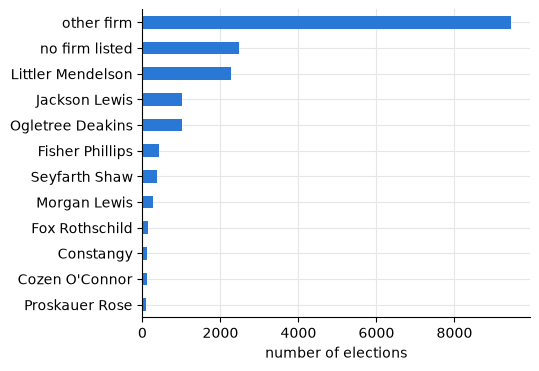

In [17]:
# the same firm is spelled several ways ("littler mendelson, p.c." / "littler mendelson pc"),
# so group by a keyword in the name, the same idea as parent_union
firm_keywords = {'littler': 'Littler Mendelson', 'ogletree': 'Ogletree Deakins', 'jackson lewis': 'Jackson Lewis',
                 'seyfarth': 'Seyfarth Shaw', 'fisher.*phillips': 'Fisher Phillips', 'morgan.*lewis': 'Morgan Lewis',
                 'constangy': 'Constangy', 'cozen': "Cozen O'Connor", 'fox rothschild': 'Fox Rothschild',
                 'proskauer': 'Proskauer Rose'}

firm_rows['firm_group'] = 'other firm'
for keyword, name in firm_keywords.items():
    firm_rows.loc[firm_rows['firm'].str.contains(keyword, na=False), 'firm_group'] = name
firm_rows.loc[firm_rows['firm'].isna(), 'firm_group'] = 'no firm listed'

plt.figure(figsize=(5,4))
firm_rows['firm_group'].value_counts().sort_values().plot.barh(color=BLUE)
plt.xlabel('number of elections')
plt.ylabel('')
plt.show()

**Observations**
- **Starbucks: 726 elections (4.7%)**, far more than any other employer. That's exactly why the
  split uses **GroupKFold by employer**: otherwise near-identical Starbucks stores would be in
  both training and validation.
- Law firms: **Littler Mendelson** shows up the most, by far. Names need cleaning first (Littler
  is spelled at least 4 ways). The keyword grouping above is a quick version.
- "no firm listed" mixes employers with no lawyer and lawyers with no firm name.

### 3.8 When: elections per month

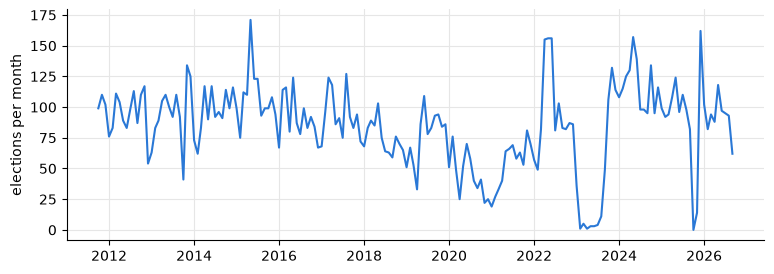

In [18]:
per_month = df.groupby(df['election_date'].dt.to_period('M')).size()
# a month with no elections has no row at all, so add every month back in with 0
per_month = per_month.reindex(pd.period_range('2011-10', '2026-09', freq='M'), fill_value=0)
per_month.index = per_month.index.to_timestamp()

plt.figure(figsize=(9,3))
plt.plot(per_month.index, per_month.values, color=BLUE)
plt.ylabel('elections per month')
plt.show()

**Observations**: the gaps are mostly about the data, not the world:
- **2023 almost disappears.** The Feb–Sep 2023 reports are image-only PDFs we couldn't read
  (`data/skipped_pdfs.txt`). The few 2023 elections left are cases that closed later.
- **2020–2021 dip**: partly COVID, and partly the FY2021 source PDFs, which only list about half
  their cases.
- **2022 jump**: the Starbucks / Workers United wave.
- **October 2025: zero elections.** This lines up with the federal government shutdown that
  month; NLRB elections are generally postponed during a shutdown. (October 2013 shows the same
  thing in section 7.)
- Right at the end (2026), elections only show up once their case has closed, so slow cases are
  still missing.

These gaps matter for the time-based split and for any plot over time.

## 4. Each feature vs. the target

For each feature: the lecture plot for its column types, then the **win rate per group**. The
gray or black line is the overall win rate (70.8%), so bars above it are groups that do better
than average.

### 4.1 Days from petition to election

share of elections within 100 days: 0.965


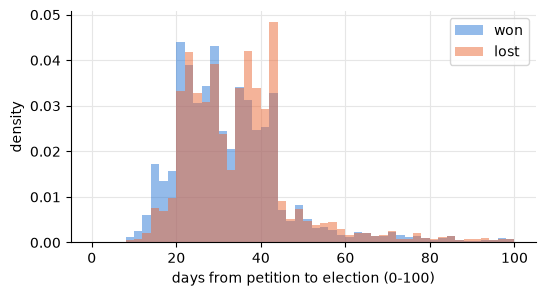

In [19]:
# category-specific histograms (lecture 4), zoomed to 0-100 days where almost all elections are
won = df[df['union_won'] == 1]['days_petition_to_election'].dropna()
lost = df[df['union_won'] == 0]['days_petition_to_election'].dropna()
print('share of elections within 100 days:', round((days <= 100).mean(), 3))

plt.figure(figsize=(6,3))
plt.hist(won, bins=50, range=(0, 100), density=True, alpha=0.5, color=BLUE, label='won')
plt.hist(lost, bins=50, range=(0, 100), density=True, alpha=0.5, color=ORANGE, label='lost')
plt.legend()
plt.xlabel('days from petition to election (0-100)')
plt.ylabel('density')
plt.show()

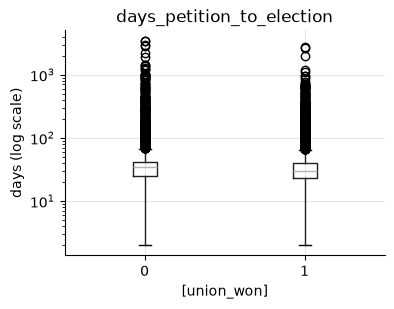

             count       mean         std  min   25%   50%   75%     max
union_won                                                               
0           4280.0  53.164953  138.029324  2.0  25.0  35.0  42.0  3444.0
1          10321.0  38.756031   63.134850  2.0  23.0  30.0  40.0  2738.0


In [20]:
df[['days_petition_to_election', 'union_won']].boxplot(by='union_won', figsize=(4,3))
plt.semilogy()
plt.suptitle('')
plt.ylabel('days (log scale)')
plt.show()

print(df.groupby('union_won')['days_petition_to_election'].describe())

              mean  size
days_bin                
(0, 14]      0.861   460
(14, 21]     0.790  2054
(21, 28]     0.714  3610
(28, 35]     0.727  2698
(35, 42]     0.651  3332
(42, 56]     0.672  1180
(56, 90]     0.693   661
(90, 180]    0.606   345
(180, 365]   0.574   148
(365, 4000]  0.434   113


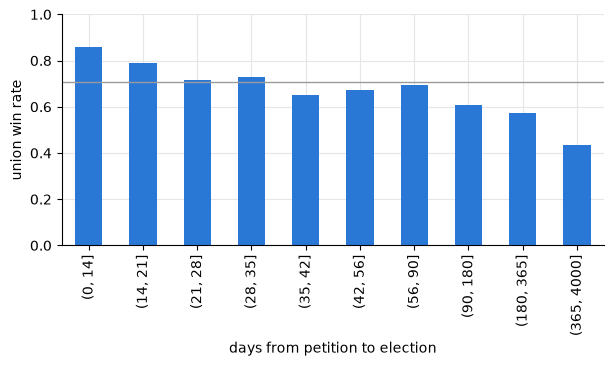

In [21]:
# win rate per bin of days
day_bins = [0, 14, 21, 28, 35, 42, 56, 90, 180, 365, 4000]
df['days_bin'] = pd.cut(df['days_petition_to_election'], day_bins)
days_table = df.groupby('days_bin', observed=True)['union_won'].agg(['mean', 'size'])
print(days_table.round(3))

plt.figure(figsize=(7,3))
days_table['mean'].plot.bar(color=BLUE)
plt.axhline(df['union_won'].mean(), color=GRAY, linewidth=1)
plt.ylim(0, 1)
plt.xlabel('days from petition to election')
plt.ylabel('union win rate')
plt.show()

In [22]:
print('win rate when days is missing:', round(df[df['days_petition_to_election'].isna()]['union_won'].mean(), 3))
print('win rate overall:            ', round(df['union_won'].mean(), 3))

win rate when days is missing: 0.729
win rate overall:             0.708


**Observations**
- In the histograms, the "lost" elections lean right (slower): median **35 days for losses vs 30
  for wins**. The two overlap a lot, which is normal for a binary target, so the histogram alone
  hides how big the effect is.
- **The win-rate plot makes it clear:** 86% won within 2 weeks, 79% at 2–3 weeks, about 65–73%
  at 3–8 weeks, 61% at 3–6 months, 57% at 6–12 months, and **43% after a year**.
- It's not perfectly smooth in the middle (5–6 weeks dips to 65%). Section 7 shows that dip
  comes from mixing different rule eras.
- Missing days (711 rows) win 72.9%, close to average, so "missing" doesn't carry much signal.
  A missing-indicator column is optional; filling with the median is fine.

### 4.2 Unit size

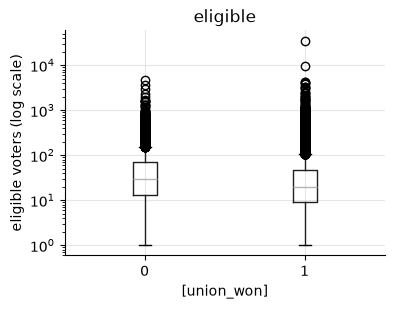

                mean  size
size_bin                  
(0, 5]         0.796  1770
(5, 10]        0.762  2248
(10, 20]       0.736  3202
(20, 50]       0.689  3970
(50, 100]      0.646  1963
(100, 250]     0.611  1377
(250, 500]     0.619   425
(500, 1000]    0.619   139
(1000, 40000]  0.738    61

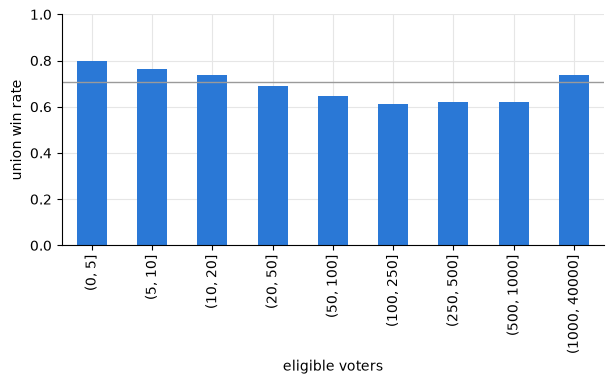

In [23]:
df[['eligible', 'union_won']].boxplot(by='union_won', figsize=(4,3))
plt.semilogy()
plt.suptitle('')
plt.ylabel('eligible voters (log scale)')
plt.show()

size_bins = [0, 5, 10, 20, 50, 100, 250, 500, 1000, 40000]
df['size_bin'] = pd.cut(df['eligible'], size_bins)
size_table = df.groupby('size_bin', observed=True)['union_won'].agg(['mean', 'size'])
print(size_table.round(3))

plt.figure(figsize=(7,3))
size_table['mean'].plot.bar(color=BLUE)
plt.axhline(df['union_won'].mean(), color=GRAY, linewidth=1)
plt.ylim(0, 1)
plt.xlabel('eligible voters')
plt.ylabel('union win rate')
plt.show()

**Observations**
- A clean downward slope: **80%** win with 5 or fewer voters, down to **61%** at 100–250
  voters. It levels off above that, and the biggest units (1000+, only 61 elections) bounce
  back up.
- Small units are easier to organize: the union knows everyone, and there's less time for a
  counter-campaign. This is one of the strongest single features (section 6).

### 4.3 Yes/no columns (stacked bar plots, lecture style)

union_won                0      1
employer_has_lawyer              
0.0                  0.149  0.851
1.0                  0.312  0.688 



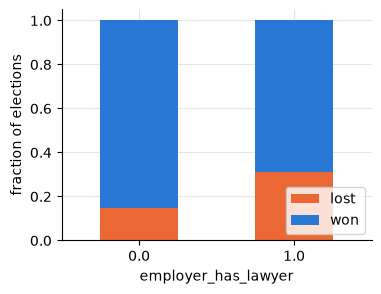

union_won                  0      1
petitioner_has_lawyer              
0.0                    0.283  0.717
1.0                    0.299  0.701 



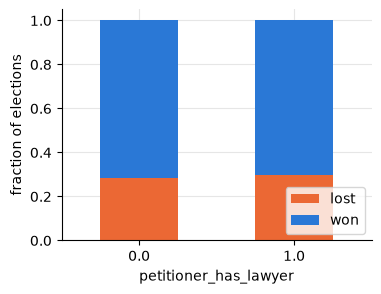

union_won           0      1
has_intervenor              
0.0             0.296  0.704
1.0             0.165  0.835 



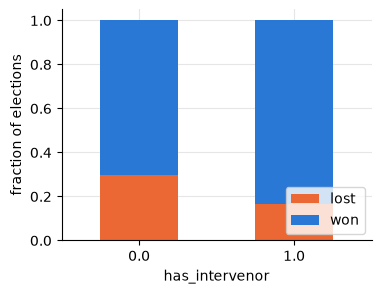

In [24]:
for col in ['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']:
    count_matrix = df.groupby([col, 'union_won']).size().unstack()
    count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
    print(count_matrix_norm.round(3), '\n')

    count_matrix_norm.plot(kind='bar', stacked=True, figsize=(4,3), color=[ORANGE, BLUE], rot=0)
    plt.ylabel('fraction of elections')
    plt.legend(['lost', 'won'], loc=4)
    plt.show()

**Observations**
- **Employer has a lawyer: 85.1% → 68.8%** union win rate, a 16-point drop. Big, and 88% of
  employers have one.
- Petitioner (union) has a lawyer: no difference (71.7% vs 70.1%).
- Intervenor: 83.5% vs 70.4%, but only 430 elections. Worth reading a few of those cases to see
  who intervenes and why.

### 4.4 Count columns

                 mean  size
n_participants             
1               1.000     1
2               0.848   607
3               0.717  3064
4               0.682  5274
5               0.698  3357
6               0.713  1782
7               0.730   734
8               0.769   489 



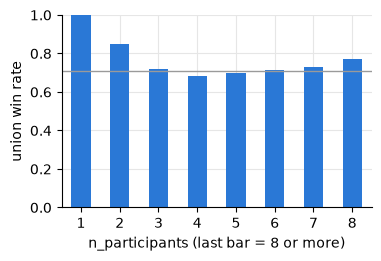

                     mean  size
n_employer_lawyers             
0                   0.851  1856
1                   0.687  8799
2                   0.674  3348
3                   0.727  1032
4                   0.736   273 



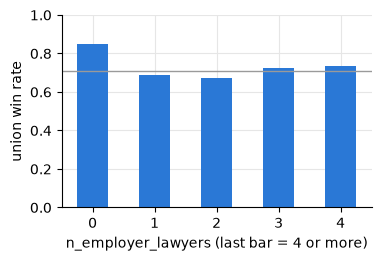

                       mean  size
n_petitioner_lawyers             
0                     0.717  6225
1                     0.698  7888
2                     0.707  1000
3                     0.831   195 



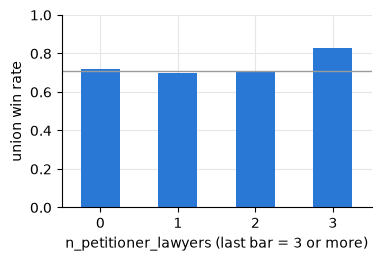

In [25]:
for col, cap in [('n_participants', 8), ('n_employer_lawyers', 4), ('n_petitioner_lawyers', 3)]:
    capped = df[col].clip(upper=cap).astype('Int64')
    table = df.groupby(capped)['union_won'].agg(['mean', 'size'])
    print(table.round(3), '\n')

    plt.figure(figsize=(4,2.5))
    table['mean'].plot.bar(color=BLUE, rot=0)
    plt.axhline(df['union_won'].mean(), color=GRAY, linewidth=1)
    plt.ylim(0, 1)
    plt.xlabel(f'{col} (last bar = {cap} or more)')
    plt.ylabel('union win rate')
    plt.show()

**Observations**
- `n_employer_lawyers`: **0 → 85%**, then about 67–74% for 1, 2, 3 or 4+. So it's *having* a
  lawyer that matters, not how many. `employer_has_lawyer` holds nearly all of this.
- `n_participants`: 2 participants win 85% (usually employer + union, no lawyers), then it's
  roughly flat (68–77%). Same lawyer effect again.
- `n_petitioner_lawyers`: flat, except 3+ (only 195 elections).

### 4.5 Parent union

                 mean  size
parent_union               
Carpenters      0.485    66
USW             0.582   409
UFCW            0.622  1059
Teamsters       0.631  3200
IBEW            0.633   931
IUPAT           0.633    79
LIUNA           0.691   233
UAW             0.691   246
Other           0.697  3288
UNITE HERE      0.733   165
IAM             0.752  1049
SPFPA           0.757   292
IUOE            0.781  1036
AFSCME          0.796   226
SEIU            0.812  1449
Workers United  0.824   865
CWA             0.834   368
Nurses          0.882   221
AFT             0.892   130


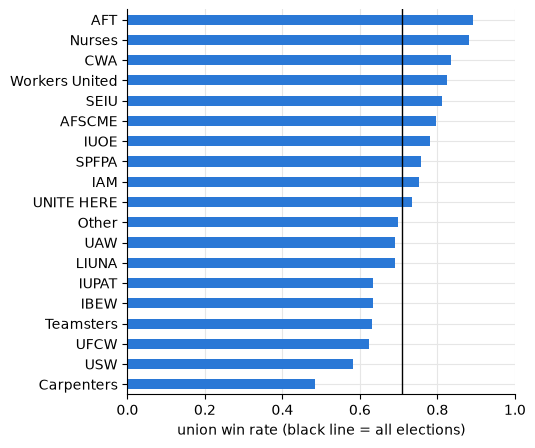

In [26]:
union_table = df.groupby('parent_union')['union_won'].agg(['mean', 'size']).sort_values('mean')
print(union_table.round(3))

plt.figure(figsize=(5,5))
union_table['mean'].plot.barh(color=BLUE)
plt.axvline(df['union_won'].mean(), color='black', linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate (black line = all elections)')
plt.ylabel('')
plt.show()

**Observations**
- The **widest spread of any feature**: AFT 89%, Nurses 88%, CWA 83%, Workers United 82%, SEIU 81%
  ... down to UFCW 62%, USW 58%, Carpenters 48%.
- My guess is that **industry** is behind this: healthcare, education and service unions do well,
  while manufacturing and construction unions do worse. We don't have an industry column, so
  `parent_union` stands in for it.
- One-hot encode it. The small groups (Carpenters n=66) are noisy.

### 4.6 Geography

                mean  size
census_region             
Midwest        0.658  3571
Territory      0.665   203
Northeast      0.715  4469
South          0.723  2835
West           0.735  4234


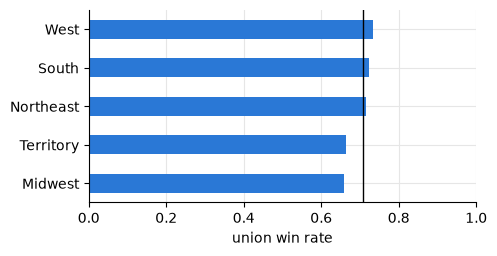

In [27]:
region_table = df.groupby('census_region')['union_won'].agg(['mean', 'size']).sort_values('mean')
print(region_table.round(3))

plt.figure(figsize=(5,2.5))
region_table['mean'].plot.barh(color=BLUE)
plt.axvline(df['union_won'].mean(), color='black', linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate')
plt.ylabel('')
plt.show()

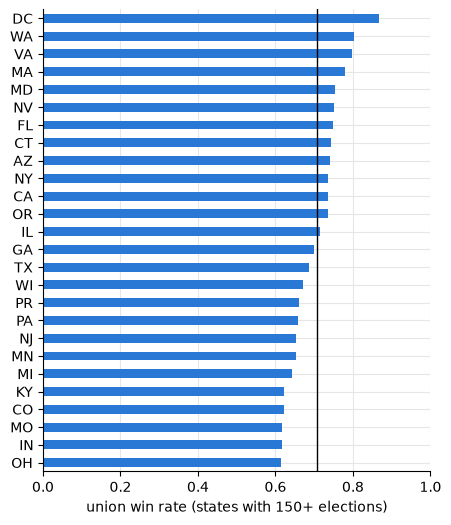

In [28]:
state_table = df.groupby('state')['union_won'].agg(['mean', 'size'])
state_table = state_table[state_table['size'] >= 150].sort_values('mean')

plt.figure(figsize=(5,6))
state_table['mean'].plot.barh(color=BLUE)
plt.axvline(df['union_won'].mean(), color='black', linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate (states with 150+ elections)')
plt.ylabel('')
plt.show()

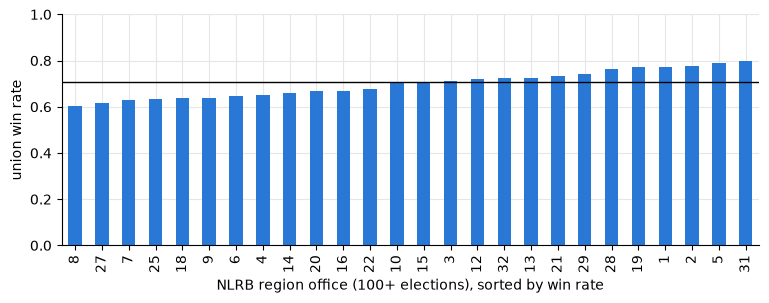

In [29]:
office_table = df.groupby('region')['union_won'].agg(['mean', 'size'])
office_table = office_table[office_table['size'] >= 100].sort_values('mean')

plt.figure(figsize=(9,3))
office_table['mean'].plot.bar(color=BLUE)
plt.axhline(df['union_won'].mean(), color='black', linewidth=1)
plt.ylim(0, 1)
plt.xlabel('NLRB region office (100+ elections), sorted by win rate')
plt.ylabel('union win rate')
plt.show()

**Observations**
- Census region: modest, 66% (Midwest) to 74% (West).
- States vary more: Ohio, Indiana and Missouri about **62%**; Washington **80%**, DC **87%**. The
  Rust Belt / Midwest is low, and the coasts are high.
- NLRB offices: about 60% to 80%. Office and state overlap a lot (each office covers a few
  states), so we probably only need one of them.

### 4.7 Employer's law firm

                    mean  size
firm_group                    
Ogletree Deakins   0.576  1007
Constangy          0.612   129
Jackson Lewis      0.624  1023
Fisher Phillips    0.632   429
Morgan Lewis       0.650   263
Fox Rothschild     0.674   144
Seyfarth Shaw      0.682   365
other firm         0.694  9461
Cozen O'Connor     0.739   111
Littler Mendelson  0.740  2264
Proskauer Rose     0.809    94
no firm listed     0.814  2489


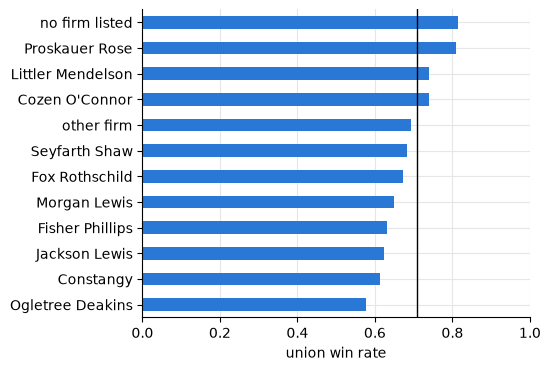

In [30]:
firm_table = firm_rows.groupby('firm_group')['union_won'].agg(['mean', 'size']).sort_values('mean')
print(firm_table.round(3))

plt.figure(figsize=(5,4))
firm_table['mean'].plot.barh(color=BLUE)
plt.axvline(df['union_won'].mean(), color='black', linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate')
plt.ylabel('')
plt.show()

**Observations**
- "no firm listed" wins the most (mostly employers with no lawyer at all, see 4.3).
- Among the big management-side firms, **Ogletree** (58%), **Constangy** (61%) and **Jackson
  Lewis** (62%) cases have lower union win rates than **Littler** (74%). That's interesting but
  not causal: firms take different kinds of clients.
- Possible feature: "big union-avoidance firm" yes/no, or a one-hot of the top ~5 firms. That
  needs name cleaning first, so it's a to-do, not a figure.

### 4.8 Time: year and month

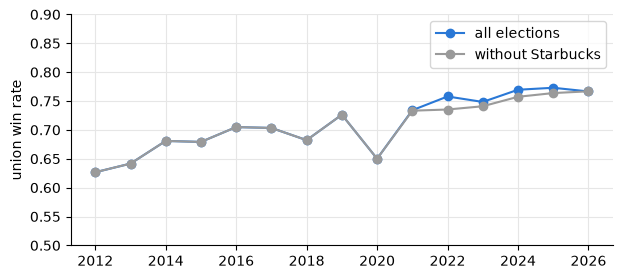

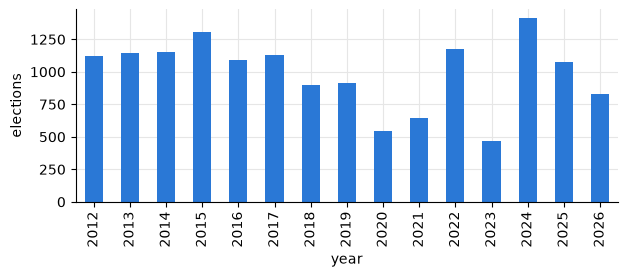

In [31]:
recent = df[df['year'] >= 2012]
by_year = recent.groupby('year')['union_won'].mean()
by_year_no_starbucks = recent[~recent['employer'].str.contains('starbucks')].groupby('year')['union_won'].mean()

plt.figure(figsize=(7,3))
plt.plot(by_year.index, by_year.values, marker='o', color=BLUE, label='all elections')
plt.plot(by_year_no_starbucks.index, by_year_no_starbucks.values, marker='o', color=GRAY, label='without Starbucks')
plt.ylim(0.5, 0.9)
plt.ylabel('union win rate')
plt.legend()
plt.show()

plt.figure(figsize=(7,2.5))
recent['year'].value_counts().sort_index().plot.bar(color=BLUE)
plt.ylabel('elections')
plt.show()

month        1         2         3         4         5        6         7         8         9         10        11        12
mean      0.719     0.704     0.703     0.723     0.733     0.71     0.727     0.693     0.713     0.689     0.693     0.687
size   1039.000  1107.000  1261.000  1301.000  1538.000  1419.00  1218.000  1298.000  1218.000  1225.000  1332.000  1356.000


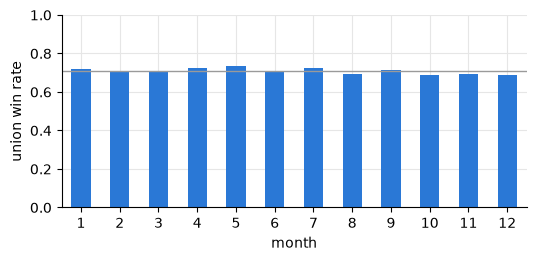

In [32]:
month_table = df.groupby('month')['union_won'].agg(['mean', 'size'])
print(month_table.round(3).T)

plt.figure(figsize=(6,2.5))
month_table['mean'].plot.bar(color=BLUE, rot=0)
plt.axhline(df['union_won'].mean(), color=GRAY, linewidth=1)
plt.ylim(0, 1)
plt.ylabel('union win rate')
plt.show()

**Observations**
- **The win rate is rising**: 63% in 2012, 73–77% from 2021 on. It's **not just Starbucks**: the
  gray line without Starbucks is almost the same.
- **This matters for the split.** If we test on the most recent years, the test set has a higher
  win rate than the training set. A model trained on 2012–2020 will under-predict wins in
  2024–2026. Mention it in the report; it also affects calibration and which baseline to compare
  against.
- A possible small bias: the latest elections only appear once their case closes, and contested
  cases (which win less) close slowly. So 2025–2026 may look a bit better than they'll end up.
- **Month: no signal** (69–73% every month). Drop it, or keep it knowing it won't help.

## 5. Pairs of features

Are the features telling us the same thing? If two features are highly correlated, only one of
them adds information.

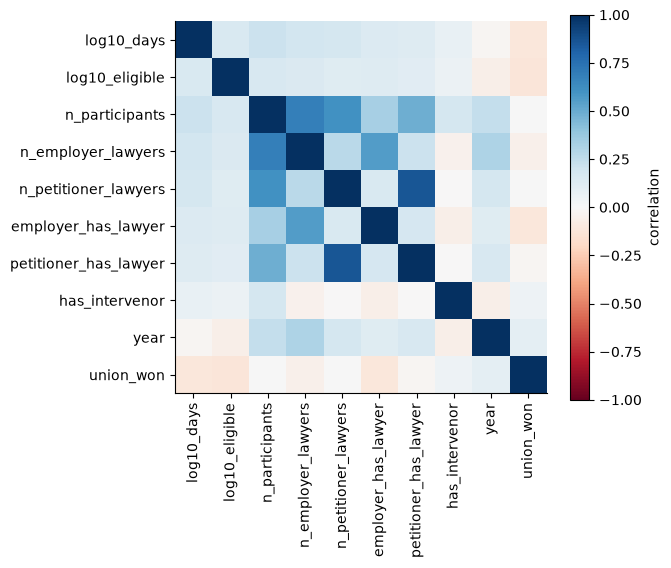

                       log10_days  log10_eligible  n_participants  n_employer_lawyers  n_petitioner_lawyers  employer_has_lawyer  petitioner_has_lawyer  has_intervenor  year  union_won
log10_days                   1.00            0.16            0.22                0.19                  0.18                 0.14                   0.13            0.07 -0.02      -0.11
log10_eligible               0.16            1.00            0.16                0.15                  0.12                 0.13                   0.11            0.06 -0.06      -0.12
n_participants               0.22            0.16            1.00                0.69                  0.60                 0.33                   0.49            0.17  0.24       0.00
n_employer_lawyers           0.19            0.15            0.69                1.00                  0.27                 0.56                   0.21           -0.04  0.31      -0.05
n_petitioner_lawyers         0.18            0.12            0.60          

In [33]:
df['log10_days'] = np.log10(df['days_petition_to_election'])
df['log10_eligible'] = np.log10(df['eligible'])

numeric_cols = ['log10_days', 'log10_eligible', 'n_participants', 'n_employer_lawyers', 'n_petitioner_lawyers',
                'employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor', 'year', 'union_won']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)   # blue = positive, red = negative, white = 0
plt.colorbar(label='correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.grid(False)
plt.show()

print(corr.round(2))

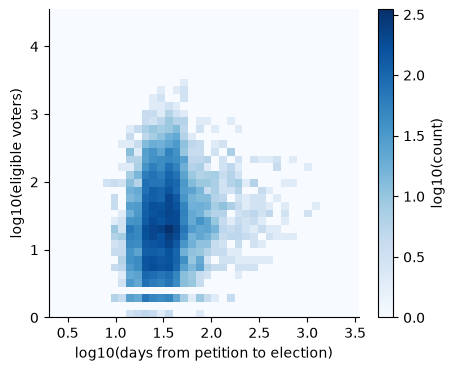

In [34]:
# heatmap of two continuous columns (lecture 4), on log scales
pair = df[['log10_days', 'log10_eligible']].dropna()
heatmap, xedges, yedges = np.histogram2d(pair['log10_days'], pair['log10_eligible'], bins=40)
heatmap[heatmap == 0] = 0.1   # we take the log and log(0) is undefined

plt.figure(figsize=(5,4))
plt.imshow(np.log10(heatmap).T, origin='lower', vmin=0, cmap='Blues', aspect='auto',
           extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])
plt.colorbar(label='log10(count)')
plt.xlabel('log10(days from petition to election)')
plt.ylabel('log10(eligible voters)')
plt.grid(False)
plt.show()

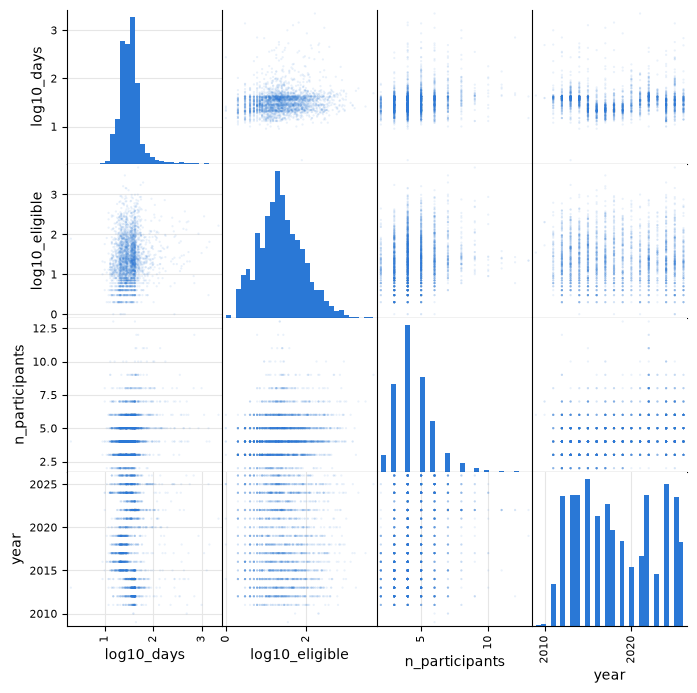

In [35]:
sample = df[['log10_days', 'log10_eligible', 'n_participants', 'year']].dropna().sample(3000, random_state=1)
pd.plotting.scatter_matrix(sample, figsize=(8,8), alpha=0.1, s=10, color=BLUE, hist_kwds={'bins': 30, 'color': BLUE})
plt.show()

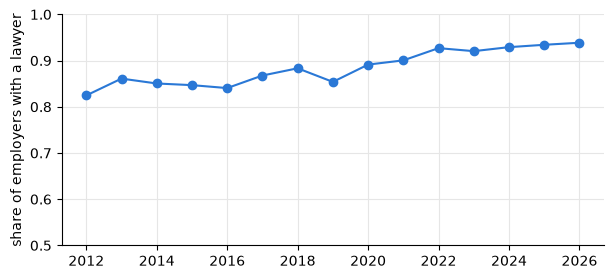

In [36]:
lawyer_by_year = recent.groupby('year')['employer_has_lawyer'].mean()

plt.figure(figsize=(7,3))
plt.plot(lawyer_by_year.index, lawyer_by_year.values, marker='o', color=BLUE)
plt.ylim(0.5, 1)
plt.ylabel('share of employers with a lawyer')
plt.show()

**Observations**
- **The features hardly overlap.** The biggest correlations are among the participant counts
  (which are built from the same list) and `n_employer_lawyers` with `year` (0.31). Days and
  unit size: 0.16. So each feature carries its own information, and there's no multicollinearity
  problem.
- The heatmap: bigger units take a bit longer, but the cloud is wide.
- **Employers are lawyering up over time**: 82% had a lawyer in 2012, 94% in 2026, while the
  union win rate went *up*. So the lawyer effect in 4.3 isn't hiding a time trend (time pushes
  the other way).
- Every single correlation with `union_won` is small (|r| ≤ 0.12). That's normal for a hard
  prediction problem; the model has to combine many weak signals.

## 6. Ranking: which features matter most?

Correlation only measures straight-line relationships and doesn't work for categories. A simple
measure that works for every feature is the **spread**: the highest group win rate minus the
lowest, using only groups with at least 100 elections so tiny groups don't win by luck.

Caveat: features with more groups (state has 26) get a bigger spread just by chance, and the
bins I picked affect it. It's a rough ranking, not a test.

petitioner has lawyer           0.016
election month                  0.045
census region (5 groups)        0.077
has intervenor                  0.131
number of petitioner lawyers    0.133
election year                   0.146
employer has lawyer             0.163
number of participants          0.166
number of employer lawyers      0.177
unit size (9 bins)              0.185
NLRB region office              0.191
state (26 with 100+)            0.253
parent union (19 groups)        0.310
days to election (10 bins)      0.427
dtype: float64


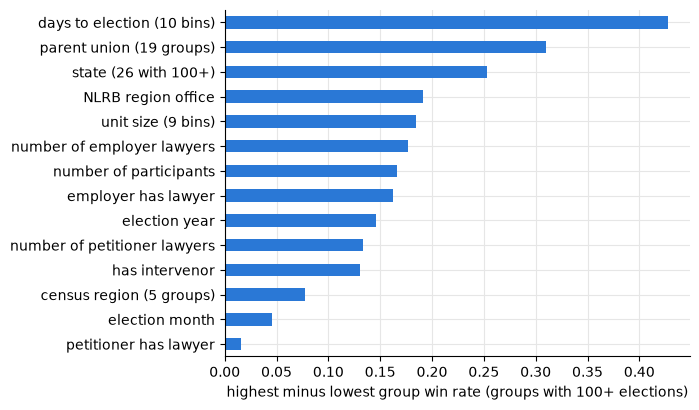

In [37]:
def win_rate_spread(column, min_size=100):
    # highest minus lowest win rate over the groups with at least min_size elections
    table = df.groupby(column, observed=True)['union_won'].agg(['mean', 'size'])
    table = table[table['size'] >= min_size]
    return table['mean'].max() - table['mean'].min()

df['n_participants_capped'] = df['n_participants'].clip(upper=8)
df['n_employer_lawyers_capped'] = df['n_employer_lawyers'].clip(upper=4)
df['n_petitioner_lawyers_capped'] = df['n_petitioner_lawyers'].clip(upper=3)

features = {'days to election (10 bins)': 'days_bin',
            'unit size (9 bins)': 'size_bin',
            'employer has lawyer': 'employer_has_lawyer',
            'petitioner has lawyer': 'petitioner_has_lawyer',
            'has intervenor': 'has_intervenor',
            'number of participants': 'n_participants_capped',
            'number of employer lawyers': 'n_employer_lawyers_capped',
            'number of petitioner lawyers': 'n_petitioner_lawyers_capped',
            'parent union (19 groups)': 'parent_union',
            'census region (5 groups)': 'census_region',
            'state (26 with 100+)': 'state',
            'NLRB region office': 'region',
            'election year': 'year',
            'election month': 'month'}

spread = pd.Series({name: win_rate_spread(col) for name, col in features.items()}).sort_values()
print(spread.round(3))

plt.figure(figsize=(6,4.5))
spread.plot.barh(color=BLUE)
plt.xlabel('highest minus lowest group win rate (groups with 100+ elections)')
plt.show()

In [38]:
corr_with_target = df[numeric_cols].corr()['union_won'].drop('union_won').sort_values()
print(corr_with_target.round(3))

log10_eligible          -0.122
employer_has_lawyer     -0.117
log10_days              -0.115
n_employer_lawyers      -0.052
petitioner_has_lawyer   -0.017
n_petitioner_lawyers     0.001
n_participants           0.001
has_intervenor           0.048
year                     0.096
Name: union_won, dtype: float64


**Ranking (my read, combining spread, correlation and how clean the pattern looks):**

| rank | feature | evidence | notes |
|---|---|---|---|
| 1 | **days to election** | 86% → 43%; r = −0.11 (log days) | holds inside every rule era (section 7) |
| 2 | **unit size** | 80% → 61%; r = −0.12 (log), the largest | clean, almost straight line |
| 3 | **employer has lawyer** | 85% → 69%; r = −0.12 | simple yes/no, easy to explain |
| 4 | **parent union** | 89% → 48% | biggest spread, but 19 groups |
| 5 | **year** | 63% → 77% | a trend: matters for the split more than as a feature |
| 6 | state / NLRB office | 62% → 87% | many groups, partly chance |
| 7 | intervenor | 70% → 84% | only 430 cases |
| — | petitioner's lawyer, month, census region | < 8 points | weak |

Days, unit size and employer lawyer are the top three, and they're **almost uncorrelated with
each other**, so they're three separate stories.

## 7. Closer look: days from petition to election

This is the feature we care about most, so before putting it in the report I want to rule out the
obvious "it's really something else" explanations:

1. **What sets the number of days?** If it's NLRB rules, it changes over time.
2. **Is it just a time effect?** Win rates rise over time (4.8). If the days pattern only shows
   up *between* eras, it's a time effect and not a days effect.
3. **Is it a proxy?** Big units take a bit longer (section 5), and so do employers with lawyers.

### 7.1 What sets the clock? Median days by the month the petition was filed

months left out (< 20 elections):
               median_days   n
petition_date                 
2020-10-01             NaN  18
2020-11-01             NaN  18
2023-01-01             NaN   2
2023-02-01             NaN   7
2023-03-01             NaN   6
2023-04-01             NaN   6
2023-05-01             NaN   8
2023-06-01             NaN   9
2023-07-01             NaN  16
2025-10-01             NaN   1


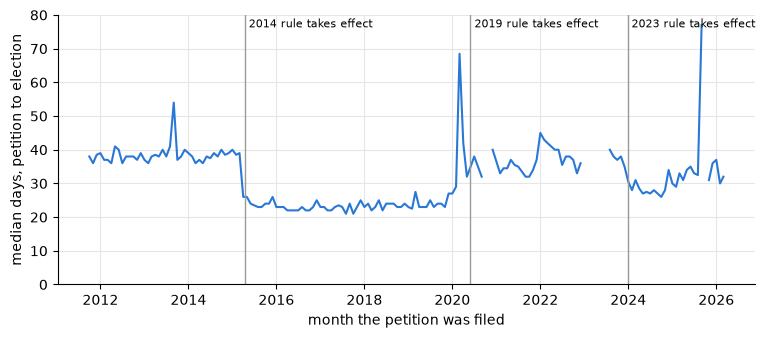

In [39]:
by_petition_month = df.groupby(df['petition_date'].dt.to_period('M')).agg(
    median_days=('days_petition_to_election', 'median'),
    n=('union_won', 'size'))

# from Oct 2011 (first report) to Mar 2026 (later petitions only have their fast elections closed so far)
by_petition_month = by_petition_month.loc['2011-10':'2026-03']
by_petition_month.loc[by_petition_month['n'] < 20, 'median_days'] = np.nan   # too few elections to trust
by_petition_month.index = by_petition_month.index.to_timestamp()
print('months left out (< 20 elections):')
print(by_petition_month[by_petition_month['median_days'].isna()])

rule_dates = {'2014 rule': '2015-04-14', '2019 rule': '2020-05-31', '2023 rule': '2023-12-26'}

plt.figure(figsize=(9,3.5))
plt.plot(by_petition_month.index, by_petition_month['median_days'], color=BLUE)
for name, date in rule_dates.items():
    plt.axvline(pd.Timestamp(date), color=GRAY, linewidth=1)
    plt.text(pd.Timestamp(date), 79, ' ' + name + ' takes effect', fontsize=8, va='top')
plt.ylim(0, 80)
plt.ylabel('median days, petition to election')
plt.xlabel('month the petition was filed')
plt.show()

**This was the most interesting finding in the exploration.** The median wait is flat for years,
then jumps exactly when an NLRB rule takes effect:

| rule | took effect (for petitions filed from) | what it did | median days after |
|---|---|---|---|
| 2014 election rule ("quickie election" rule) | **April 14, 2015** | removed waiting periods, sped up hearings | 38 → **23** |
| 2019 election rule | **May 31, 2020** (delayed from April by COVID; a court struck some parts the day before) | added back waiting time | 23 → **37** (COVID mail ballots too) |
| 2023 election rule | **December 26, 2023** | mostly restored the 2014 rule | 37 → **30** |

Dates checked on 2026-10-23 against the Federal Register and NLRB notices, plus law-firm
summaries for the 2019 rule's delay (sources in the to-do list, section 9).

- **Three one-month spikes**, each one a pause in elections:
  - Sep 2013 (54 days): petitions filed just before the October 2013 federal government shutdown;
  - Mar 2020 (68 days): the NLRB paused elections for COVID;
  - Sep 2025 (77 days): just before the October 2025 shutdown (zero elections that month, see 3.8).
- Months with fewer than 20 elections are left out (the line breaks there): the **2023 missing
  reports**, Oct–Nov 2020 (the thin FY2021 reports) and Oct 2025 (the shutdown).
- **Why this matters:** days to election is something **policy controls**. If faster elections
  really do help unions, the rules change outcomes. (We can't prove the causal part with this
  data, but it makes the feature worth studying.)

### 7.2 The four rule eras

In [40]:
era_edges = pd.to_datetime(['1990-01-01', '2015-04-14', '2020-05-31', '2023-12-26', '2030-01-01'])
era_names = ['before Apr 2015', 'Apr 2015 – May 2020', 'May 2020 – Dec 2023', 'since Dec 2023']
df['era'] = pd.cut(df['petition_date'], era_edges, labels=era_names, right=False)

era_table = df.groupby('era', observed=True).agg(median_days=('days_petition_to_election', 'median'),
                                                win_rate=('union_won', 'mean'),
                                                n=('union_won', 'size'))
print(era_table.round(3))

                     median_days  win_rate     n
era                                             
before Apr 2015             38.0     0.654  4218
Apr 2015 – May 2020         23.0     0.698  4914
May 2020 – Dec 2023         37.0     0.736  2464
since Dec 2023              30.0     0.771  3009


The era with the fastest elections (2015–2020, median 23 days) does **not** have the highest
win rate; the latest era does. So **between** eras, speed and win rate don't line up, because
the rising trend from 4.8 dominates. The question is what happens **within** each era.

### 7.3 Within each era: do faster elections still win more?

era        before Apr 2015  Apr 2015 – May 2020  May 2020 – Dec 2023  since Dec 2023
speed_bin                                                                           
≤3 wk                0.835                0.782                0.907           0.835
3–4 wk               0.816                0.659                0.785           0.780
4–5 wk               0.726                0.640                0.746           0.779
5–6 wk               0.602                0.681                0.709           0.761
6 wk–3 mo            0.638                0.662                0.704           0.726
>3 mo                0.486                0.552                0.685           0.538 

era        before Apr 2015  Apr 2015 – May 2020  May 2020 – Dec 2023  since Dec 2023
speed_bin                                                                           
≤3 wk                  176                 1702                  140             496
3–4 wk                 385                 2099                

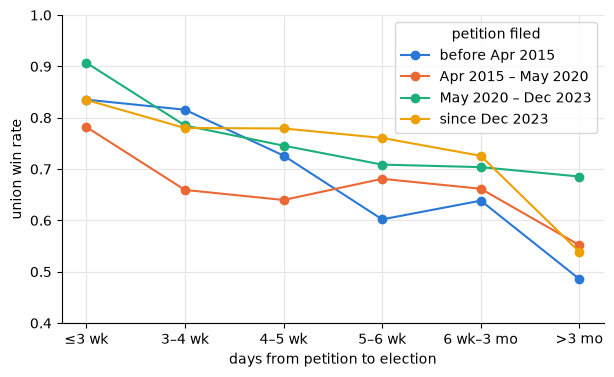

In [41]:
speed_bins = [0, 21, 28, 35, 42, 90, 4000]
speed_labels = ['≤3 wk', '3–4 wk', '4–5 wk', '5–6 wk', '6 wk–3 mo', '>3 mo']
df['speed_bin'] = pd.cut(df['days_petition_to_election'], speed_bins, labels=speed_labels)

within_era = df.groupby(['speed_bin', 'era'], observed=True)['union_won'].mean().unstack()
within_era_n = df.groupby(['speed_bin', 'era'], observed=True).size().unstack()
print(within_era.round(3), '\n')
print(within_era_n)

era_colors = [BLUE, ORANGE, '#1baf7a', '#eda100']
plt.figure(figsize=(7,4))
for era, color in zip(era_names, era_colors):
    plt.plot(speed_labels, within_era[era], marker='o', color=color, label=era)
plt.ylim(0.4, 1)
plt.ylabel('union win rate')
plt.xlabel('days from petition to election')
plt.legend(title='petition filed')
plt.show()

**Observations**
- **Yes. In every era, the fastest group has the highest win rate, and the slowest group (> 3
  months) has the lowest.** The lines go down from left to right in all four eras.
- Each line has its own level (later eras are higher, the time trend), but the downward slope
  shows up in all of them. So **days isn't just a time effect.**
- That explains the 5–6 week dip in 4.1: most 5–6 week elections are from before 2015 (2,045 of
  3,332), which is also the era with the lowest win rate overall.
- Some cells are small (e.g. 163 elections at 5–6 weeks in 2015–2020, when almost everything was
  faster), so the lines wiggle.

### 7.4 Is days a proxy for unit size or for lawyers?

size_group  ≤10 voters  11–30  31–100   >100
speed_bin                                   
≤3 wk            0.821  0.807   0.769  0.788
3–4 wk           0.778  0.732   0.666  0.593
4–5 wk           0.782  0.750   0.686  0.632
5–6 wk           0.753  0.683   0.591  0.539
6 wk–3 mo        0.733  0.707   0.634  0.637
>3 mo            0.642  0.593   0.526  0.556


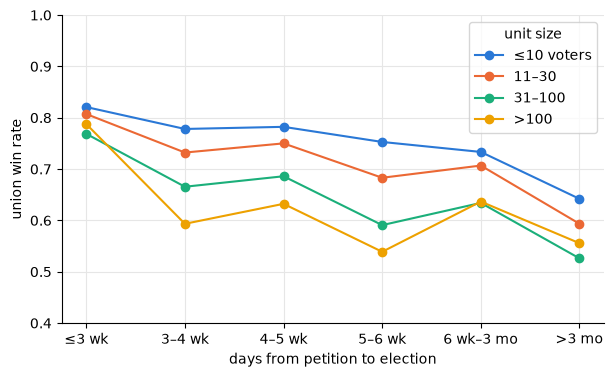

In [42]:
df['size_group'] = pd.cut(df['eligible'], [0, 10, 30, 100, 40000], labels=['≤10 voters', '11–30', '31–100', '>100'])
by_size = df.groupby(['speed_bin', 'size_group'], observed=True)['union_won'].mean().unstack()
print(by_size.round(3))

plt.figure(figsize=(7,4))
for group, color in zip(by_size.columns, era_colors):
    plt.plot(speed_labels, by_size[group], marker='o', color=color, label=group)
plt.ylim(0.4, 1)
plt.ylabel('union win rate')
plt.xlabel('days from petition to election')
plt.legend(title='unit size')
plt.show()

In [43]:
df['speed_half'] = pd.cut(df['days_petition_to_election'], [0, 31, 4000],
                          labels=['≤ 31 days (faster half)', '> 31 days (slower half)'])
lawyer_speed = df.groupby(['employer_has_lawyer', 'speed_half'], observed=True)['union_won'].agg(['mean', 'size'])
print(lawyer_speed.round(3))
print()
print(df.groupby('employer_has_lawyer')['days_petition_to_election'].median())

                                              mean  size
employer_has_lawyer speed_half                          
0.0                 ≤ 31 days (faster half)  0.868  1181
                    > 31 days (slower half)  0.811   608
1.0                 ≤ 31 days (faster half)  0.723  6138
                    > 31 days (slower half)  0.654  6670



employer_has_lawyer
0.0    27.0
1.0    33.0
Name: days_petition_to_election, dtype: float64


**Observations**
- **Unit size:** within each size group, faster still wins more. Smaller units are higher overall,
  and the slope is there in all four, steepest for the big units (79% → 56%).
- **Lawyers:** employers with lawyers *are* slower (median 33 vs 27 days), but within each group
  the faster half still wins more: **87% vs 81%** with no lawyer, **72% vs 65%** with a lawyer.
  The two effects add up: no lawyer + fast = 87%, lawyer + slow = 65%.
- So days, unit size and lawyers are three **separate** signals, which is good for the model.

**The causal story (be careful in the report).** One likely explanation is that a contested case
is *both* slower and more likely to be lost: the employer asks for a hearing, files objections,
and runs a longer campaign. So days partly measures how hard the employer fights. The data shows
**an association**, not that speed itself causes wins. The docket file
(`docket_activity_merged.csv`) has hearings and requests for review, which could help separate the
two later (they happen before the vote, but they aren't known on the petition date).

**When is days known?** The election date is set before the vote, so days is known at prediction
time if we predict "just before the vote". If we wanted to predict on the day the petition is
filed, we couldn't use it. Worth one sentence in the report.

### 7.5 Two small checks: the 42-day spike and the missing days

In [44]:
print('eras of the elections held exactly 42 days after the petition:')
print(df[df['days_petition_to_election'] == 42]['era'].value_counts(normalize=True).round(3))
print()
print('elections with no days value, by year:')
print(df[df['days_petition_to_election'].isna()].groupby('year').size())

eras of the elections held exactly 42 days after the petition:
era
before Apr 2015        0.726
May 2020 – Dec 2023    0.145
since Dec 2023         0.098
Apr 2015 – May 2020    0.031
Name: proportion, dtype: float64

elections with no days value, by year:
year
2004     1
2008     1
2009     1
2011    25
2012    17
2013    24
2014    18
2015    32
2016    53
2017    69
2018    45
2019    84
2020    35
2021    34
2022    59
2023    28
2024    71
2025    62
2026    52
dtype: int64


- **73% of the 42-day elections are from before April 2015.** So the 6-week spike is a scheduling
  habit of the old rules.
- The 711 missing days are spread over all years (the public docket doesn't list every petition,
  `data_checks.md` check 19). Nothing to fix; impute in the pipeline.

**Summary for days to election:** a strong, believable signal that holds within eras, unit sizes
and lawyer groups; set by NLRB policy; an association, not proof of cause. It deserves the
headline figure.

## 8. Candidate explanatory figures for the report

From lecture 4: explanatory figures are high stakes, so **the message must be clear**. For each
candidate:
- the **title is the message** (a headline, not "win rate vs days"), and a gray subtitle says what's
  plotted;
- one color (blue), gray for reference lines, and bigger fonts than the exploration plots;
- labels only where they help, and sample sizes in the tick labels so readers know which bars are
  small;
- each figure is saved to `../figures/` at 300 dpi for the report.

There are 7 candidates. My top 3 are in section 9.

In [45]:
def add_headline(headline, subtitle):
    # bold headline (the message) plus a gray subtitle (what is plotted), above the axes
    plt.title(headline, loc='left', fontsize=14, fontweight='bold', pad=30)
    plt.text(0, 1.03, subtitle, transform=plt.gca().transAxes, fontsize=9.5, color='#555555', va='bottom')

### Candidate A: days to election vs win rate (**the main one**)

**Message:** the longer it takes to get from petition to vote, the less likely the union wins.
Six wider bins make it a clean staircase (the 10-bin version in 4.1 has a wiggle in the middle
caused by mixing eras).

                     mean  size
wait                           
≤ 2 weeks           0.861   460
2–3 weeks           0.790  2054
3–6 weeks           0.696  9640
6 weeks–\n3 months  0.680  1841
3–12\nmonths        0.596   493
> 1 year            0.434   113


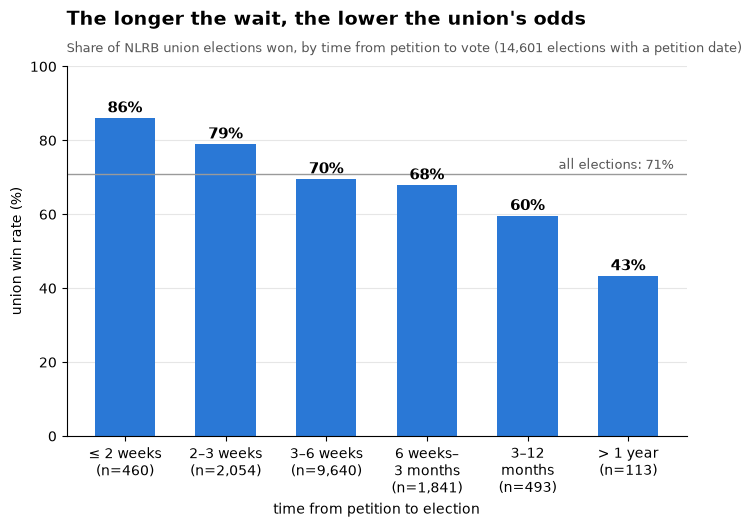

In [46]:
wait_bins = [0, 14, 21, 42, 90, 365, 4000]
wait_labels = ['≤ 2 weeks', '2–3 weeks', '3–6 weeks', '6 weeks–\n3 months', '3–12\nmonths', '> 1 year']
df['wait'] = pd.cut(df['days_petition_to_election'], wait_bins, labels=wait_labels)
wait_table = df.groupby('wait', observed=True)['union_won'].agg(['mean', 'size'])
print(wait_table.round(3))

tick_labels = [f'{label}\n(n={n:,})' for label, n in zip(wait_table.index, wait_table['size'])]
win_pct = wait_table['mean'] * 100
overall_pct = df['union_won'].mean() * 100

plt.figure(figsize=(8,4.8))
plt.bar(tick_labels, win_pct, color=BLUE, width=0.6)
plt.axhline(overall_pct, color=GRAY, linewidth=1)
plt.text(5.45, overall_pct + 1.5, f'all elections: {overall_pct:.0f}%', ha='right', fontsize=9, color='#555555')
for i, pct in enumerate(win_pct):
    plt.text(i, pct + 1.5, f'{pct:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('union win rate (%)')
plt.xlabel('time from petition to election')
plt.grid(axis='x', visible=False)
add_headline("The longer the wait, the lower the union's odds",
             'Share of NLRB union elections won, by time from petition to vote (14,601 elections with a petition date)')
plt.savefig('../figures/eda_A_days_win_rate.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate B: the NLRB's rules set the clock

**Message:** the median wait moves only when the NLRB changes its rules. It pairs well with A:
A says speed is linked to winning, B says policy sets the speed.

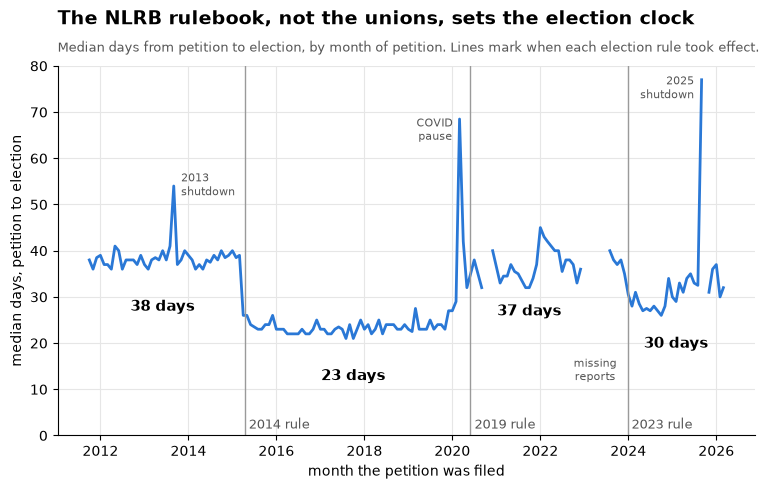

In [47]:
plt.figure(figsize=(9,4.8))
plt.plot(by_petition_month.index, by_petition_month['median_days'], color=BLUE, linewidth=2)
for name, date in rule_dates.items():
    plt.axvline(pd.Timestamp(date), color=GRAY, linewidth=1)
    plt.text(pd.Timestamp(date), 1.5, ' ' + name, fontsize=9, color='#555555')

# label each era with its median, under the line near the middle of the era
era_middles = ['2013-06-01', '2017-10-01', '2021-10-01', '2025-02-01']
for middle, med in zip(era_middles, era_table['median_days']):
    plt.text(pd.Timestamp(middle), med - 11, f'{med:.0f} days', ha='center', fontsize=11, fontweight='bold')

# small gray notes for the one-month spikes and the gap
plt.text(pd.Timestamp('2013-11-01'), 52, '2013\nshutdown', fontsize=8, color='#555555')
plt.text(pd.Timestamp('2020-01-01'), 64, 'COVID\npause', fontsize=8, color='#555555', ha='right')
plt.text(pd.Timestamp('2025-07-01'), 73, '2025\nshutdown', fontsize=8, color='#555555', ha='right')
plt.text(pd.Timestamp('2023-04-01'), 12, 'missing\nreports', ha='center', fontsize=8, color='#555555')

plt.ylim(0, 80)
plt.ylabel('median days, petition to election')
plt.xlabel('month the petition was filed')
add_headline('The NLRB rulebook, not the unions, sets the election clock',
             'Median days from petition to election, by month of petition. Lines mark when each election rule took effect.')
plt.savefig('../figures/eda_B_rules_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate C: faster wins more under every set of rules

**Message:** the pattern in A isn't a time trend; it shows up within each rule era. This is the
"what about X?" backup for A. It's denser, so maybe use it in an appendix or the presentation
rather than as one of the 3.

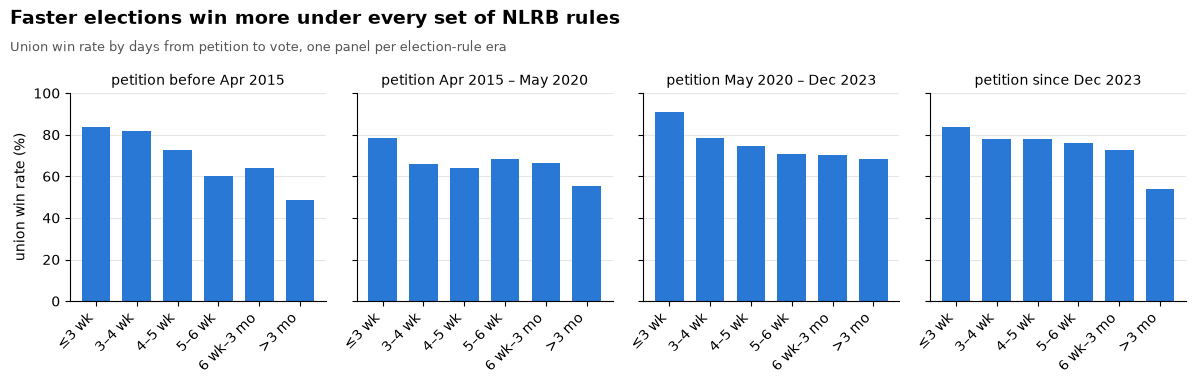

In [48]:
fig, axes = plt.subplots(1, 4, figsize=(12,4), sharey=True)
for ax, era in zip(axes, era_names):
    ax.bar(range(len(speed_labels)), within_era[era] * 100, color=BLUE, width=0.7)
    ax.set_xticks(range(len(speed_labels)))
    ax.set_xticklabels(speed_labels, rotation=45, ha='right')
    ax.set_title('petition ' + era, fontsize=10)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('union win rate (%)')
axes[0].set_ylim(0, 100)
fig.suptitle('Faster elections win more under every set of NLRB rules', x=0.01, y=0.98, ha='left',
             fontsize=14, fontweight='bold')
fig.text(0.01, 0.875, 'Union win rate by days from petition to vote, one panel per election-rule era',
         fontsize=9.5, color='#555555')
fig.subplots_adjust(left=0.06, right=0.99, top=0.77, bottom=0.25, wspace=0.12)
plt.savefig('../figures/eda_C_days_within_eras.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate D: small units win more

**Message:** the smaller the bargaining unit, the better the union's odds. It's the strongest
single correlation.

          mean  size
unit                
≤ 5      0.796  1770
6–10     0.762  2248
11–20    0.736  3202
21–50    0.689  3970
51–100   0.646  1963
101–250  0.611  1377
> 250    0.630   625


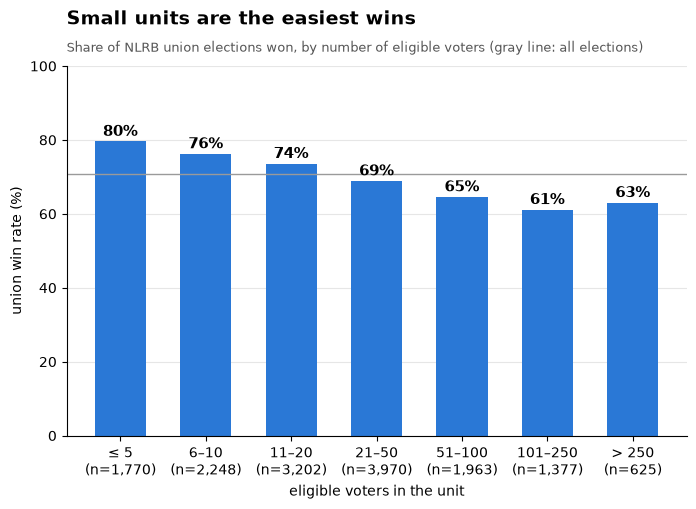

In [49]:
unit_bins = [0, 5, 10, 20, 50, 100, 250, 40000]
unit_labels = ['≤ 5', '6–10', '11–20', '21–50', '51–100', '101–250', '> 250']
df['unit'] = pd.cut(df['eligible'], unit_bins, labels=unit_labels)
unit_table = df.groupby('unit', observed=True)['union_won'].agg(['mean', 'size'])
print(unit_table.round(3))

tick_labels = [f'{label}\n(n={n:,})' for label, n in zip(unit_table.index, unit_table['size'])]
win_pct = unit_table['mean'] * 100

plt.figure(figsize=(8,4.8))
plt.bar(tick_labels, win_pct, color=BLUE, width=0.6)
plt.axhline(overall_pct, color=GRAY, linewidth=1)
for i, pct in enumerate(win_pct):
    plt.text(i, pct + 1.5, f'{pct:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('union win rate (%)')
plt.xlabel('eligible voters in the unit')
plt.grid(axis='x', visible=False)
add_headline('Small units are the easiest wins',
             'Share of NLRB union elections won, by number of eligible voters (gray line: all elections)')
plt.savefig('../figures/eda_D_unit_size.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate E: lawyers and delay add up

**Message:** when the employer has a lawyer, the union's odds drop, and a slow election drops
them further. It brings in a second feature and also shows that days isn't just a stand-in for
lawyers.

speed_half              ≤ 31 days (faster half)  > 31 days (slower half)
employer had no lawyer                     86.8                     81.1
employer had a lawyer                      72.3                     65.4


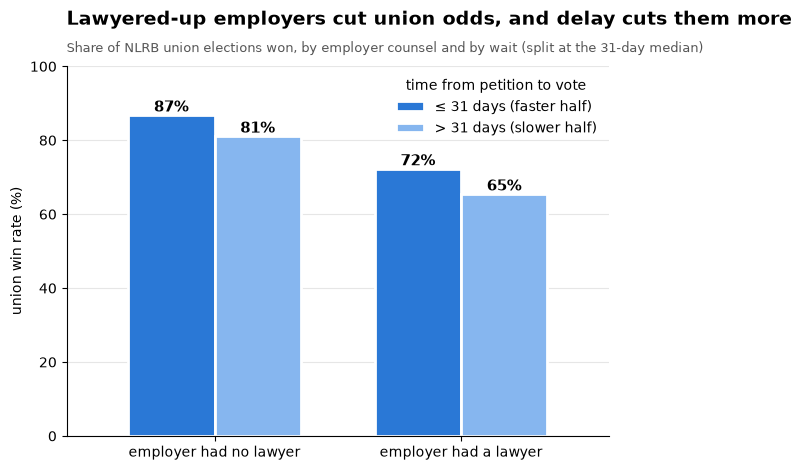

In [50]:
lawyer_table = df.groupby(['employer_has_lawyer', 'speed_half'], observed=True)['union_won'].mean().unstack() * 100
lawyer_table.index = ['employer had no lawyer', 'employer had a lawyer']
print(lawyer_table.round(1))

ax = lawyer_table.plot.bar(color=[BLUE, LIGHT_BLUE], figsize=(7,4.8), rot=0, width=0.7,
                           edgecolor='white', linewidth=2)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('union win rate (%)')
plt.xlabel('')
plt.grid(axis='x', visible=False)
plt.legend(title='time from petition to vote', loc='upper right', frameon=False)
add_headline('Lawyered-up employers cut union odds, and delay cuts them more',
             'Share of NLRB union elections won, by employer counsel and by wait (split at the 31-day median)')
plt.savefig('../figures/eda_E_lawyer_and_speed.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate F: unions are winning more often

**Message:** the base rate is moving. It's useful in the report because it explains a modeling
choice (time-based split, the test years have a higher win rate), not just a fact about the data.

year
2012    62.7
2013    64.2
2014    68.1
2015    67.9
2016    70.5
2017    70.3
2018    68.2
2019    72.6
2020    65.0
2021    73.4
2022    75.8
2023    74.8
2024    77.0
2025    77.3
2026    76.7
Name: union_won, dtype: float64


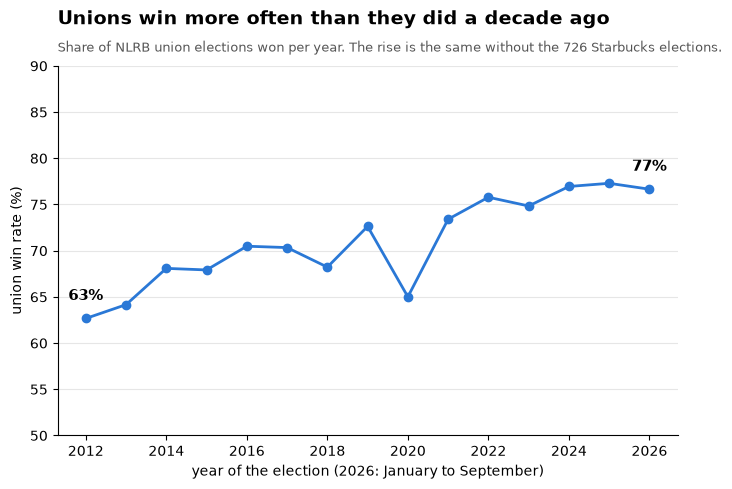

In [51]:
win_by_year = recent.groupby('year')['union_won'].mean() * 100
print(win_by_year.round(1))

plt.figure(figsize=(8,4.8))
plt.plot(win_by_year.index, win_by_year.values, color=BLUE, linewidth=2, marker='o')
for year in [2012, 2026]:   # label the two ends only
    plt.text(year, win_by_year[year] + 2, f'{win_by_year[year]:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(50, 90)
plt.xticks(range(2012, 2027, 2))
plt.grid(axis='x', visible=False)
plt.ylabel('union win rate (%)')
plt.xlabel('year of the election (2026: January to September)')
add_headline('Unions win more often than they did a decade ago',
             'Share of NLRB union elections won per year. The rise is the same without the 726 Starbucks elections.')
plt.savefig('../figures/eda_F_win_rate_by_year.png', dpi=300, bbox_inches='tight')
plt.show()

### Candidate G: who is organizing matters

**Message:** the biggest spread of any feature. Nurses and teachers almost always win; carpenters
win less than half the time.

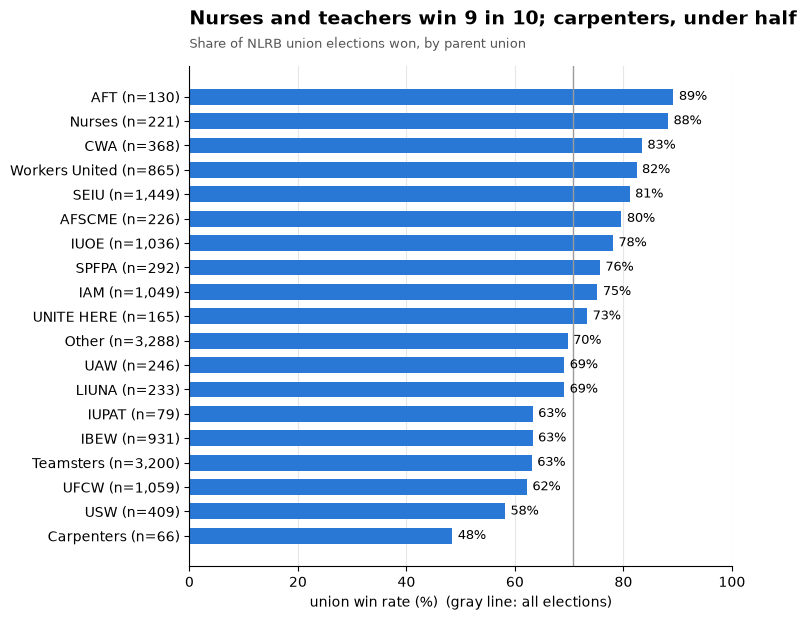

In [52]:
union_pct = union_table['mean'] * 100
labels = [f'{name} (n={n:,})' for name, n in zip(union_table.index, union_table['size'])]

plt.figure(figsize=(7,6.5))
plt.barh(labels, union_pct, color=BLUE, height=0.65)
plt.axvline(overall_pct, color=GRAY, linewidth=1)
for i, pct in enumerate(union_pct):
    plt.text(pct + 1, i, f'{pct:.0f}%', va='center', fontsize=9)
plt.xlim(0, 100)
plt.xlabel('union win rate (%)  (gray line: all elections)')
plt.grid(axis='y', visible=False)
add_headline('Nurses and teachers win 9 in 10; carpenters, under half',
             'Share of NLRB union elections won, by parent union')
plt.savefig('../figures/eda_G_parent_union.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Recommendations and to-dos

### Which 3 figures for the midterm report

My pick, in this order:

1. **A: "The longer the wait, the lower the union's odds."** Our main feature, a simple staircase,
   one number per bar. This should be the first figure.
2. **E: "Lawyered-up employers cut union odds, and delay cuts them more."** It brings in the
   second strong feature (employer lawyer), and it backs up A by showing days isn't just a
   stand-in for lawyers.
3. **F: "Unions win more often than they did a decade ago."** It connects the EDA to the ML
   setup: with a time-based split, the test years have a higher win rate than training. Graders
   like EDA that leads into a modeling decision.

**Other options:**
- If the report's story is centered on days, **use B instead of F**. "The NLRB rulebook sets the
  clock" is the most interesting finding, and A + B together make a nice two-step argument (policy
  → speed → outcomes). F's point can be one sentence in the splitting section.
- **D (unit size)** is the cleanest pattern and the strongest single correlation. It's a good
  swap for E if we want simpler figures.
- **C** is the robustness check for A. Keep it for the presentation or appendix, or mention it in
  one sentence ("the pattern holds within each rule era").
- **G** is eye-catching, but with 19 groups it's busier, and the message ("industry matters") is a
  guess we can't check.

### Notes for preprocessing and feature engineering
- `days_petition_to_election`: use `log10` or cap at about 180 days for linear models; 711
  missing → median impute (+ optional missing flag). Consider adding the **rule era** as a
  categorical feature (known from the petition date).
- `eligible`: `log10`; 157 missing → impute.
- `employer_has_lawyer` holds the lawyer signal; `n_employer_lawyers` adds little.
  `petitioner_has_lawyer` is weak but cheap to keep.
- `parent_union`: one-hot (19 groups). `state` vs `region` vs `census_region`: pick one or two;
  merge tiny categories.
- `month`: no signal.
- Law firms: normalize the names first (keyword map in 3.7), then maybe flag the top firms.
- `year`: the win rate drifts upward. With a time split, keep this in mind for the baseline (the
  test-set base rate is ~77%, not 71%) and for calibration.

### Caveats to mention in the report
- **Missing months**: Feb–Sep 2023 reports unreadable, FY2021 reports about half empty. Visible as
  gaps in any time plot.
- **End of the data**: recent elections only appear once their case closes, and slow, contested
  cases are missing for now.
- **Association, not causation**: speed is probably partly a measure of how hard the employer
  contests the election.
- Elections before Oct 2011 are only cases that closed late (unusual).

### Open questions / to-dos
- [ ] Who are the intervenors (430 cases, 84% win rate)?
- [ ] Are elections held within 2 weeks (460) real, or are some petition dates off? Spot-check a
  few dockets.
- [ ] Hearing / request-for-review flags from the docket: do they explain the days effect?
- [ ] Pick the final 3 as a team, then polish (fonts, size for the report's column width).
- [ ] Sources for the rule dates (checked 2026-10-23):
  [Federal Register: 2023 rule](https://www.federalregister.gov/documents/2023/08/25/2023-18129/representation-case-procedures/),
  [NLRB: representation case procedures](https://nlrb.gov/about-nlrb/what-we-do/representation-case-procedures),
  [Littler on the 2019 rule taking effect](https://littler.com/node/571111),
  [Stinson on the court ruling](https://www.stinson.com/newsroom-publications-New-NLRB-Election-Rules-Partially-Invalidated).
  For the October 2025 shutdown: [Foley, Oct 2025](https://www.foley.com/insights/publications/2025/10/navigating-nlra-compliance-during-the-government-shutdown/).